小学算法

In [13]:
import numpy as np


def process_sign(x: str, y: str) -> tuple[str, str, int]:
    """处理负号"""
    x, sign_x = (x[1:], -1) if x and x[0] == "-" else (x, 1)
    y, sign_y = (y[1:], -1) if y and y[0] == "-" else (y, 1)
    sign = sign_x * sign_y
    return x, y, sign


def grade_school(x: str, y: str) -> str:
    x, y, sign = process_sign(x, y)
    x_len, y_len = len(x), len(y)

    x = x[::-1]  # 逆序 低位在前、高位在后

    # 数字字符串 => 整数数组 例如 "123" => [1,2,3]
    x = np.frombuffer(x.encode(), dtype=np.uint8) - 48
    y = np.frombuffer(y.encode(), dtype=np.uint8) - 48

    # 为做卷积 第一个输入参数两端补零
    x = np.pad(x, pad_width=(y_len-1, y_len-1))

    # 计算卷积 x[0]y[0], x[0]y[1] + x[1]y[0], ...
    l = x_len + y_len - 1
    conv = np.zeros(l, dtype=np.int64)
    for i in range(l):
        for j in range(y_len):
            conv[i] += x[i+j] * y[j]

    h = 0  # 初始进位为零
    z = []
    for c in conv:
        c += h
        h, q = divmod(c, 10)
        z.append(q)
    while h:
        h, q = divmod(h, 10)
        z.append(q)

    # 反向并去掉高位零
    s = ''.join(map(str, reversed(z))).lstrip('0') or '0'
    return ('-' + s) if sign < 0 and s != '0' else s


x, y = "45234566344567567456785677856789", "-346785749876556788967895678"
z0 = grade_school(x, y)
z0

'-15686703010141722186958835868043878006906999203618376057942'

Karatsuba 算法

In [14]:
def align(x: str, y: str) -> tuple[str, str]:
    """左补零到等长"""
    if len(x) < len(y):
        x = x.rjust(len(y), "0")
    else:
        y = y.rjust(len(x), "0")
    return x, y, len(x)


def karatsuba(x: str, y: str) -> int:
    x, y, sign = process_sign(x, y)
    x, y, n = align(x, y)

    if n <= 1:
        v = int(x) * int(y)
        return sign * v

    m = n // 2
    a, b = x[:n - m], x[n - m:]  # x = a * 10^m + b
    c, d = y[:n - m], y[n - m:]  # y = c * 10^m + d

    ai, bi, ci, di = int(a), int(b), int(c), int(d)
    ac = karatsuba(a, c)
    bd = karatsuba(b, d)
    ad_bc = karatsuba(str(ai + bi), str(ci + di)) - ac - bd

    pow10 = 10 ** m
    v = ac * pow10 * pow10 + ad_bc * pow10 + bd
    return sign * v


x, y = "45234566344567567456785677856789", "-346785749876556788967895678"
z1 = karatsuba(x, y)
z1

-15686703010141722186958835868043878006906999203618376057942

Toom 算法

In [15]:
def toom(x: str, y: str) -> int:
    x, y, sign = process_sign(x, y)
    x, y, n = align(x, y)

    if n <= 2:
        v = int(x) * int(y)
        return sign * v

    m = n // 3

    a, b, c = x[:n - 2 * m], x[n - 2 * m:n - m], x[n - m:]
    d, e, f = y[:n - 2 * m], y[n - 2 * m:n - m], y[n - m:]

    ai, bi, ci = int(a), int(b), int(c)
    di, ei, fi = int(d), int(e), int(f)

    # 5个递归子问题
    s4 = toom(a, d)
    s3 = toom(str(4 * ai + 2 * bi + ci), str(4 * di + 2 * ei + fi))
    s2 = toom(str(ai - bi + ci), str(di - ei + fi))
    s1 = toom(str(ai + bi + ci), str(di + ei + fi))
    s0 = toom(c, f)

    w4 = s4
    w3 = (-12 * s4 + s3 - s2 - 3 * s1 + 3 * s0) // 6
    w2 = (-2 * s4 + s2 + s1 - 2 * s0) // 2
    w1 = (12 * s4 - s3 - 2 * s2 + 6 * s1 - 3 * s0) // 6
    w0 = s0

    p1 = 10 ** m
    p2 = p1 * p1
    v = w4*p2*p2 + w3*p2*p1 + w2*p2 + w1*p1 + w0
    return sign * v


x, y = "45234566344567567456785677856789", "-346785749876556788967895678"
z2 = karatsuba(x, y)
z2

-15686703010141722186958835868043878006906999203618376057942

In [ ]:
import string
import time
import sys
sys.set_int_max_str_digits(1000000)
import random
random.seed(0)

trial = 12
time_cost = np.empty((trial, 3))
for t in range(trial):
    n = 2**(t + 5)

    # 随机生成长度为n的字符串x和y
    x = ''.join(random.choices(string.digits, k=n))
    y = ''.join(random.choices(string.digits, k=n))

    z0 = int(x) * int(y)

    start = time.perf_counter()
    z1 = grade_school(x, y)
    time_cost[t, 0] = time.perf_counter() - start

    start = time.perf_counter()
    z2 = karatsuba(x, y)
    time_cost[t, 1] = time.perf_counter() - start

    start = time.perf_counter()
    z3 = toom(x, y)
    time_cost[t, 2] = time.perf_counter() - start

np.save('integer-multiplication-time-cost.npy', time_cost)

[[9.09901000e-04 4.58401000e-04 4.68402000e-04]
 [3.34027100e-03 1.43639700e-03 9.69171000e-04]
 [1.38430310e-02 4.54337600e-03 2.48536600e-03]
 [5.76143910e-02 1.31869580e-02 9.61465700e-03]
 [2.34073212e-01 4.04343300e-02 2.23623430e-02]
 [9.45050000e-01 1.24873065e-01 5.73436070e-02]
 [3.81118606e+00 3.69206149e-01 1.50330903e-01]
 [1.51626905e+01 1.10554054e+00 3.74257836e-01]
 [6.06307337e+01 3.35430794e+00 1.48748129e+00]
 [2.42022079e+02 9.92283104e+00 3.17732282e+00]
 [9.66541503e+02 3.08393361e+01 8.66783434e+00]
 [3.86551182e+03 9.00878213e+01 3.25476450e+01]]


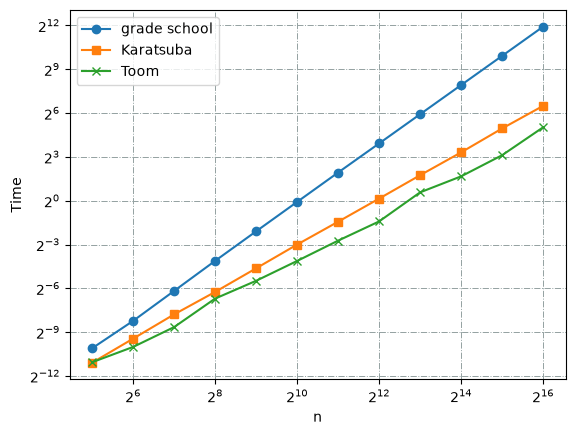

In [20]:
import matplotlib.pyplot as plt

time_cost = np.load('integer-multiplication-time-cost.npy')
print(time_cost)
trial = time_cost.shape[0]

n = [2**(t + 5) for t in range(trial)]
plt.loglog(n, time_cost[:, 0], base=2, marker='o', label="grade school")
plt.loglog(n, time_cost[:, 1], base=2, marker='s', label="Karatsuba")
plt.loglog(n, time_cost[:, 2], base=2, marker='x', label="Toom")
plt.xlabel("n")
plt.ylabel("Time")
plt.grid(color='#93a1a1', linestyle='-.', linewidth=0.7)
plt.legend()
plt.show()